# OILTRACE AI — AIS Notebook (final)
**Vessel-traffic cleaning · behaviour-anomaly model · explainable candidate attribution · SAR–AIS consistency**

This notebook is the AIS half of OILTRACE AI. It is **independent of the CNN notebook** (no image code, no
shared variables) and produces everything the backend's `/ais/candidates` and `/attribute` endpoints need.

| Output file | Used for |
|---|---|
| `oiltrace_ais.py` | importable backend module (cleaning, model, attribution, SAR–AIS check) |
| `ais_anomaly_model.joblib` + `ais_anomaly_model_meta.json` | trained behaviour model with fixed score calibration |
| `demo_ais_arabian_sea.csv` | synthetic AIS for the demo incident (6 fictional vessels) |
| `ais_incident_result.json` | frozen result contract: ranking, evidence, SAR–AIS, slider positions |
| `OILTRACE_AIS_HANDOFF.zip` | everything above in one download |

**What changed versus the old combined notebook**
1. **AIS "not available" codes are no longer treated as data.** `SOG = 102.3`, `COG = 360`, `Heading = 511` made the old
   top-ranked vessel look anomalous purely because of a missing-value flag. They are now recovered from the position track.
2. Tracks are split at gaps; features are computed only *inside* a segment (no 73-day "time gaps").
3. Location-independent behaviour features (no raw COG/lat/lon) → a model trained on one sea can score another.
4. **One** scoring function — the 7-factor, spec-weighted attribution (20/25/20/15/10/5/5) — instead of five variants.
5. Fixed score calibration (comparable across candidates) instead of per-batch min–max / 2-vessel percentiles.
6. Candidate search is driven by **source region × release window**, not by the visible slick.
7. SAR–AIS consistency module (matched / potential AIS-dark vessels).
8. Synthetic Arabian-Sea demo incident + time-slider data, generated here and scored by the *real* engine.

**Scope boundaries (by design)**: the backward hindcast / forward forecast drift model belongs to the backend
`drift_model.py`; this notebook *consumes* its output (`SourceRegion` + release window).

> ⚠️ *Prototype Attribution Score — an investigation aid, not a legal determination of responsibility.*
> The anomaly model is unsupervised: "anomalous" means statistically unusual, not proven wrongdoing.

## 1. Setup

In [1]:
# In Google Colab nothing needs installing (pandas, numpy, scikit-learn, scipy, matplotlib are preinstalled).
# Elsewhere:  pip install pandas numpy scikit-learn scipy matplotlib joblib
import os, sys, json, glob, subprocess, shutil, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn, scipy

RANDOM_STATE = 42
OUT_DIR = "OILTRACE_AIS_models"
os.makedirs(OUT_DIR, exist_ok=True)

# Real historical AIS used to TRAIN the behaviour model (US Gulf of Mexico, Dec-2020..Mar-2021).
# Leave None to auto-detect; or set to your own CSV path (columns: MMSI, BaseDateTime, LAT, LON, SOG, COG, ...).
AIS_CSV = None
REPO_URL = "https://github.com/Saisamarth21/Oil-Spill-Detection-in-Marine-Environments-Using-AIS-and-Satellite-Data.git"
REPO_DIR = "_oiltrace_repo"

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

python 3.12.3 | pandas 2.2.3 | numpy 2.5.4 | scikit-learn 1.8.0 | scipy 1.18.1


In [2]:
def locate_training_csv():
    cands = [AIS_CSV, "/content/ais_dataset.csv", "ais_dataset.csv"] + glob.glob(f"{REPO_DIR}/AIS Dataset/*.csv")
    for c in cands:
        if c and os.path.isfile(c):
            return c
    if not os.path.isdir(REPO_DIR):
        print("Cloning the public AIS repository (needs internet) ...")
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    found = glob.glob(f"{REPO_DIR}/AIS Dataset/*.csv")
    if not found:
        raise FileNotFoundError("No AIS CSV found. Upload one and set AIS_CSV = '/path/to/file.csv'.")
    return found[0]

TRAIN_CSV = locate_training_csv()
print("Training AIS file:", TRAIN_CSV)

Training AIS file: _oiltrace_repo/AIS Dataset/AIS_172433991588466433_2317-1724339916028.csv


## 2. The deployable module (`oiltrace_ais.py`)
Everything below imports this file, so the notebook and the backend run **identical** code.

In [3]:
%%writefile oiltrace_ais.py
"""
OILTRACE AI - AIS module
========================
Self-contained, backend-importable module (no notebook state needed).

Pipeline
    raw AIS  ->  clean_ais()  ->  build_features()  ->  AISAnomalyModel.score()
    source region + release window  ->  attribute_vessels()  ->  ranked, explainable candidates
    SAR vessel detections  ->  sar_ais_consistency()  ->  matched / AIS-dark vessels

IMPORTANT (scientific honesty)
    * The anomaly model is UNSUPERVISED. "Anomalous" means "statistically unusual
      compared with the training traffic", not "violated a rule".
    * The attribution score is a PROTOTYPE, hand-weighted heuristic. It is not
      validated against ground-truth spills and is NOT a legal determination.
"""
from __future__ import annotations

import json
import math
import os
import warnings
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd

__all__ = [
    "AIS_SOG_NA", "AIS_COG_NA", "AIS_HEADING_NA", "FEATURES", "WEIGHTS", "DISCLAIMER",
    "haversine_km", "bearing_deg", "standardize_columns", "clean_ais", "build_features",
    "AISAnomalyModel", "SourceRegion", "interpolate_track", "attribute_vessels",
    "sar_ais_consistency", "to_jsonable",
]

# --------------------------------------------------------------------------
# Constants
# --------------------------------------------------------------------------
AIS_SOG_NA = 102.3        # AIS code: speed over ground "not available"
AIS_COG_NA = 360.0        # AIS code: course over ground "not available"
AIS_HEADING_NA = 511      # AIS code: true heading "not available"
MAX_PLAUSIBLE_SOG = 50.0  # knots; above this a value is treated as corrupt
SEGMENT_GAP_MIN = 15.0    # a gap longer than this starts a new track segment
MIN_DT_MIN = 0.5          # lower bound for dt when converting differences to rates
MAX_INTERP_GAP_MIN = 15.0 # do not interpolate across an AIS gap longer than this

# Behaviour features: location independent on purpose (no lat/lon/raw COG), so a model
# trained on one sea area can score traffic in another.
FEATURES = ["sog", "accel_kn_per_min", "turn_rate_deg_per_min", "speed_mismatch_kn"]

# Attribution weights (must sum to 100) - taken from the OILTRACE specification.
WEIGHTS = {
    "time_match": 20,
    "source_overlap": 25,
    "trajectory": 20,
    "distance": 15,
    "behaviour": 10,
    "ais_consistency": 5,
    "vessel_relevance": 5,
}
assert sum(WEIGHTS.values()) == 100

DISCLAIMER = ("Prototype Attribution Score - an investigation aid, not a legal determination "
              "of responsibility. 'Anomalous' means statistically unusual, not proven wrongdoing.")

_COLUMN_MAP = {
    "mmsi": "mmsi", "basedatetime": "time", "timestamp": "time", "time": "time",
    "datetime": "time", "lat": "lat", "latitude": "lat", "lon": "lon", "lng": "lon",
    "longitude": "lon", "sog": "sog", "speed": "sog", "cog": "cog", "course": "cog",
    "heading": "heading", "vesselname": "vessel_name", "vessel_name": "vessel_name",
    "name": "vessel_name", "vesseltype": "vessel_type", "vessel_type": "vessel_type",
    "status": "status", "imo": "imo", "length": "length", "width": "width",
    "vessel_id": "vessel_id",
}


# --------------------------------------------------------------------------
# Geometry helpers
# --------------------------------------------------------------------------
def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km (vectorised)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def bearing_deg(lat1, lon1, lat2, lon2):
    """Initial bearing from point 1 to point 2 in degrees [0, 360) (vectorised)."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    dlon = lon2 - lon1
    x = np.sin(dlon) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
    return (np.degrees(np.arctan2(x, y)) + 360.0) % 360.0


def _angle_diff(a, b):
    """Smallest absolute difference between two bearings (degrees)."""
    d = np.abs(np.asarray(a, float) - np.asarray(b, float)) % 360.0
    return np.minimum(d, 360.0 - d)


def _local_km(lat, lon, lat0, lon0):
    """Equirectangular projection to km around (lat0, lon0)."""
    x = (np.asarray(lon, float) - lon0) * 111.320 * math.cos(math.radians(lat0))
    y = (np.asarray(lat, float) - lat0) * 110.574
    return x, y


# --------------------------------------------------------------------------
# 1. Cleaning
# --------------------------------------------------------------------------
def standardize_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Rename common AIS column spellings to the canonical lowercase names."""
    rename = {}
    for c in df.columns:
        key = str(c).strip().lower().replace(" ", "")
        if key in _COLUMN_MAP and _COLUMN_MAP[key] not in rename.values():
            rename[c] = _COLUMN_MAP[key]
    out = df.rename(columns=rename).copy()
    missing = [c for c in ("mmsi", "time", "lat", "lon", "sog") if c not in out.columns]
    if missing:
        raise ValueError(f"AIS data is missing required columns: {missing}")
    for c in ("cog", "heading", "vessel_name", "vessel_type", "status"):
        if c not in out.columns:
            out[c] = np.nan
    return out


def _implied_motion(df: pd.DataFrame) -> pd.DataFrame:
    """Add implied speed (knots) / bearing from consecutive positions (df sorted by mmsi,time)."""
    g = df.groupby("mmsi", sort=False)
    plat, plon, ptime = g["lat"].shift(1), g["lon"].shift(1), g["time"].shift(1)
    dt_h = (df["time"] - ptime).dt.total_seconds() / 3600.0
    dist = haversine_km(plat, plon, df["lat"], df["lon"])
    ok = (dt_h > 0) & (dt_h * 60 <= SEGMENT_GAP_MIN)
    df["implied_speed_kn"] = np.where(ok, dist / 1.852 / dt_h.where(dt_h > 0), np.nan)
    df["implied_bearing"] = np.where(ok, bearing_deg(plat, plon, df["lat"], df["lon"]), np.nan)
    # fall back to the NEXT record for the first row of each segment
    nxt_speed = df.groupby("mmsi", sort=False)["implied_speed_kn"].shift(-1)
    nxt_bear = df.groupby("mmsi", sort=False)["implied_bearing"].shift(-1)
    df["implied_speed_kn"] = df["implied_speed_kn"].fillna(nxt_speed)
    df["implied_bearing"] = df["implied_bearing"].fillna(nxt_bear)
    return df


def clean_ais(raw: pd.DataFrame) -> Tuple[pd.DataFrame, Dict[str, int]]:
    """
    Clean raw AIS records.

    * canonical column names, UTC-naive timestamps, de-duplication, sorting
    * drops impossible coordinates (incl. AIS codes lat=91 / lon=181)
    * AIS "not available" codes (SOG 102.3, COG 360, heading 511) are NOT treated as data:
      they are set to NaN, and SOG/COG are then RECOVERED from the position track when possible
    * rows whose SOG cannot be recovered are dropped
    * adds track-segment ids (new segment after a gap > SEGMENT_GAP_MIN)

    Returns (clean_df, report) where report counts what was changed.
    """
    df = standardize_columns(raw)
    rep: Dict[str, int] = {"input_rows": int(len(df))}

    df["time"] = pd.to_datetime(df["time"], errors="coerce", utc=True).dt.tz_localize(None)
    for c in ("lat", "lon", "sog", "cog", "heading"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["mmsi"] = pd.to_numeric(df["mmsi"], errors="coerce")

    before = len(df)
    df = df.dropna(subset=["mmsi", "time", "lat", "lon"])
    df = df[df["lat"].between(-90, 90) & df["lon"].between(-180, 180)]
    df = df[~((df["lat"] == 91) | (df["lon"] == 181) | ((df["lat"] == 0) & (df["lon"] == 0)))]
    rep["dropped_invalid_position_or_time"] = int(before - len(df))

    before = len(df)
    df = df.drop_duplicates(["mmsi", "time"]).sort_values(["mmsi", "time"]).reset_index(drop=True)
    df["mmsi"] = df["mmsi"].astype("int64")
    rep["dropped_duplicates"] = int(before - len(df))

    # --- AIS sentinel codes -> NaN
    sog_bad = df["sog"].isna() | (df["sog"] >= AIS_SOG_NA) | (df["sog"] < 0) | (df["sog"] > MAX_PLAUSIBLE_SOG)
    cog_bad = df["cog"].isna() | (df["cog"] >= AIS_COG_NA) | (df["cog"] < 0)
    rep["sog_sentinel_or_invalid"] = int(sog_bad.sum())
    rep["cog_sentinel_or_invalid"] = int(cog_bad.sum())
    df.loc[sog_bad, "sog"] = np.nan
    df.loc[cog_bad, "cog"] = np.nan
    df.loc[(df["heading"] >= 360) | (df["heading"] < 0), "heading"] = np.nan

    # --- recover SOG / COG from the track
    df = _implied_motion(df)
    can_sog = df["sog"].isna() & df["implied_speed_kn"].between(0, MAX_PLAUSIBLE_SOG)
    df["sog_recovered"] = can_sog
    df.loc[can_sog, "sog"] = df.loc[can_sog, "implied_speed_kn"]
    can_cog = df["cog"].isna() & df["implied_bearing"].notna() & (df["implied_speed_kn"] > 0.5)
    df["cog_recovered"] = can_cog
    df.loc[can_cog, "cog"] = df.loc[can_cog, "implied_bearing"]
    rep["sog_recovered_from_track"] = int(can_sog.sum())
    rep["cog_recovered_from_track"] = int(can_cog.sum())

    before = len(df)
    df = df.dropna(subset=["sog"]).reset_index(drop=True)
    rep["dropped_unrecoverable_sog"] = int(before - len(df))

    # --- segments (split at long gaps)
    gap_min = df.groupby("mmsi", sort=False)["time"].diff().dt.total_seconds() / 60.0
    new_seg = gap_min.isna() | (gap_min > SEGMENT_GAP_MIN)
    df["segment_id"] = new_seg.cumsum().astype("int64")
    rep["output_rows"] = int(len(df))
    rep["vessels"] = int(df["mmsi"].nunique())
    rep["segments"] = int(df["segment_id"].nunique())
    return df, rep


# --------------------------------------------------------------------------
# 2. Behaviour features
# --------------------------------------------------------------------------
def build_features(clean: pd.DataFrame) -> pd.DataFrame:
    """
    Add behaviour features computed ONLY inside a track segment (never across long gaps).
    The first row of every segment has no previous point and gets NaN features.
    """
    df = clean.copy()
    g = df.groupby("segment_id", sort=False)
    dt_min = (g["time"].diff().dt.total_seconds() / 60.0).clip(lower=MIN_DT_MIN)
    d_sog = g["sog"].diff().abs()
    df["accel_kn_per_min"] = d_sog / dt_min
    cog_prev = g["cog"].shift(1)
    turn = _angle_diff(df["cog"], cog_prev)
    # COG is meaningless at (almost) zero speed - do not call a drifting hull "turning"
    slow = (df["sog"] < 0.5) | (g["sog"].shift(1) < 0.5)
    df["turn_rate_deg_per_min"] = np.where(slow, 0.0, turn / dt_min)
    mism = (df["implied_speed_kn"] - df["sog"]).abs()
    df["speed_mismatch_kn"] = mism.fillna(0.0).clip(upper=MAX_PLAUSIBLE_SOG)
    df["dt_min"] = dt_min
    first = g.cumcount() == 0
    for c in ("accel_kn_per_min", "turn_rate_deg_per_min"):
        df.loc[first, c] = np.nan
    df.loc[first, "speed_mismatch_kn"] = np.nan
    return df


# --------------------------------------------------------------------------
# 3. Anomaly model (Isolation Forest + calibrated 0-100 score)
# --------------------------------------------------------------------------
class AISAnomalyModel:
    """
    Isolation Forest on FEATURES with a FIXED score calibration learned on the training data.

    score_0_100 = 0 at the training median "unusualness", 100 at the training 99.5th percentile
    (clipped). Because the calibration is stored, scores are comparable across calls/candidates -
    unlike per-batch min-max normalisation.
    """

    def __init__(self, n_estimators: int = 300, contamination: float = 0.02, random_state: int = 42):
        self.n_estimators = n_estimators
        self.contamination = contamination
        self.random_state = random_state
        self.scaler = None
        self.detector = None
        self.calib = None
        self.meta: Dict = {}

    @staticmethod
    def _matrix(feat: pd.DataFrame) -> pd.DataFrame:
        x = feat[FEATURES].replace([np.inf, -np.inf], np.nan)
        return x

    def fit(self, feat: pd.DataFrame) -> "AISAnomalyModel":
        import sklearn
        from sklearn.ensemble import IsolationForest
        from sklearn.preprocessing import StandardScaler

        x = self._matrix(feat).dropna()
        self.scaler = StandardScaler().fit(x.values)
        self.detector = IsolationForest(
            n_estimators=self.n_estimators, contamination=self.contamination,
            random_state=self.random_state, n_jobs=-1,
        ).fit(self.scaler.transform(x.values))
        raw = -self.detector.decision_function(self.scaler.transform(x.values))
        self.calib = {"lo": float(np.percentile(raw, 50)), "hi": float(np.percentile(raw, 99.5))}
        self.meta = {
            "features": FEATURES,
            "n_training_rows": int(len(x)),
            "contamination": self.contamination,
            "n_estimators": self.n_estimators,
            "sklearn_version": sklearn.__version__,
            "calibration": self.calib,
            "score_definition": "0 = training-median unusualness, 100 = training 99.5th percentile (clipped)",
        }
        return self

    def score(self, feat: pd.DataFrame) -> pd.DataFrame:
        """Return DataFrame(index=feat.index) with anomaly_score (0-100) and is_anomaly (bool).
        Rows with missing features get score NaN / is_anomaly False."""
        x = self._matrix(feat)
        ok = x.notna().all(axis=1)
        out = pd.DataFrame({"anomaly_score": np.nan, "is_anomaly": False}, index=feat.index)
        if ok.any():
            xs = self.scaler.transform(x[ok].values)
            raw = -self.detector.decision_function(xs)
            lo, hi = self.calib["lo"], self.calib["hi"]
            out.loc[ok, "anomaly_score"] = 100.0 * np.clip((raw - lo) / (hi - lo), 0, 1)
            out.loc[ok, "is_anomaly"] = self.detector.predict(xs) == -1
        return out

    def save(self, directory: str, name: str = "ais_anomaly_model") -> str:
        import joblib
        os.makedirs(directory, exist_ok=True)
        path = os.path.join(directory, f"{name}.joblib")
        joblib.dump({"scaler": self.scaler, "detector": self.detector, "calib": self.calib,
                     "meta": self.meta}, path)
        with open(os.path.join(directory, f"{name}_meta.json"), "w", encoding="utf-8") as f:
            json.dump(self.meta, f, indent=2)
        return path

    @classmethod
    def load(cls, path: str) -> "AISAnomalyModel":
        import joblib
        import sklearn
        blob = joblib.load(path)
        m = cls()
        m.scaler, m.detector, m.calib, m.meta = blob["scaler"], blob["detector"], blob["calib"], blob["meta"]
        trained = m.meta.get("sklearn_version")
        if trained and trained != sklearn.__version__:
            warnings.warn(f"Model trained with scikit-learn {trained}, running {sklearn.__version__}. "
                          "Pin the version or retrain.")
        if list(m.meta.get("features", [])) != FEATURES:
            raise ValueError("Saved model feature list does not match oiltrace_ais.FEATURES")
        return m


# --------------------------------------------------------------------------
# 4. Source region + track interpolation
# --------------------------------------------------------------------------
@dataclass
class SourceRegion:
    """Probable source region produced by the backward hindcast (a probabilistic REGION, not a point)."""
    lat: float
    lon: float
    radius_km: float
    polygon: Optional[Sequence[Tuple[float, float]]] = None  # optional [(lat, lon), ...]

    def distance_km(self, lat, lon):
        return haversine_km(self.lat, self.lon, lat, lon)

    def _inside_polygon(self, lat, lon):
        px, py = _local_km(lat, lon, self.lat, self.lon)
        vx, vy = _local_km([p[0] for p in self.polygon], [p[1] for p in self.polygon], self.lat, self.lon)
        inside = np.zeros(np.shape(px), dtype=bool)
        n = len(vx)
        j = n - 1
        for i in range(n):
            cond = ((vy[i] > py) != (vy[j] > py)) & (
                px < (vx[j] - vx[i]) * (py - vy[i]) / (vy[j] - vy[i] + 1e-12) + vx[i])
            inside ^= cond
            j = i
        return inside

    def membership(self, lat, lon):
        """Soft membership in [0,1]: 1 inside the region, falling linearly to 0 at 2x the radius."""
        d = self.distance_km(lat, lon)
        m = np.clip(1.0 - (d - self.radius_km) / max(self.radius_km, 1e-6), 0.0, 1.0)
        if self.polygon:
            m = np.maximum(m, self._inside_polygon(lat, lon).astype(float))
        return m


def interpolate_track(vessel: pd.DataFrame, times: pd.DatetimeIndex,
                      max_gap_min: float = MAX_INTERP_GAP_MIN) -> pd.DataFrame:
    """
    Linearly interpolate a vessel's lat/lon at `times`.
    `covered` is False outside the observed span or where the bracketing AIS reports are more than
    `max_gap_min` apart (we never invent positions across an AIS gap).
    """
    v = vessel.sort_values("time")
    t_obs = v["time"].values.astype("datetime64[s]").astype("int64").astype(float)
    t_q = pd.DatetimeIndex(times).values.astype("datetime64[s]").astype("int64").astype(float)
    out = pd.DataFrame({"time": pd.DatetimeIndex(times)})
    if len(v) < 2:
        out["lat"] = np.nan
        out["lon"] = np.nan
        out["covered"] = False
        return out
    out["lat"] = np.interp(t_q, t_obs, v["lat"].values, left=np.nan, right=np.nan)
    out["lon"] = np.interp(t_q, t_obs, v["lon"].values, left=np.nan, right=np.nan)
    idx = np.searchsorted(t_obs, t_q, side="right")
    lo = np.clip(idx - 1, 0, len(t_obs) - 1)
    hi = np.clip(idx, 0, len(t_obs) - 1)
    bracket_gap_min = (t_obs[hi] - t_obs[lo]) / 60.0
    exact = np.isin(t_q, t_obs)
    out["covered"] = (~np.isnan(out["lat"].values)) & ((bracket_gap_min <= max_gap_min) | exact)
    out.loc[~out["covered"], ["lat", "lon"]] = np.nan
    return out


# --------------------------------------------------------------------------
# 5. Attribution engine
# --------------------------------------------------------------------------
_RELEVANCE = [  # (low, high, score, label)
    (80, 89, 1.00, "Tanker"),
    (70, 79, 0.70, "Cargo ship"),
    (90, 99, 0.40, "Other"),
    (60, 69, 0.30, "Passenger"),
    (30, 30, 0.30, "Fishing"),
    (31, 32, 0.45, "Towing"),
    (52, 52, 0.45, "Tug"),
    (35, 35, 0.20, "Military"),
    (36, 37, 0.10, "Pleasure craft"),
]


def _vessel_relevance(vessel_type) -> Tuple[float, str]:
    """Heuristic: how plausible is this ship class as an oil source? Unknown type -> neutral 0.4."""
    try:
        t = int(float(vessel_type))
    except (TypeError, ValueError):
        return 0.4, "Unknown type"
    for lo, hi, score, label in _RELEVANCE:
        if lo <= t <= hi:
            return score, label
    return 0.4, f"Type {t}"


def _grade(x: float) -> str:
    return "Excellent" if x >= 0.85 else "Good" if x >= 0.60 else "Fair" if x >= 0.35 else "Poor"


def _level(x: float) -> str:
    return "High" if x >= 0.60 else "Medium" if x >= 0.30 else "Low"


def _hhmm(ts) -> str:
    return pd.Timestamp(ts).strftime("%H:%M")


def attribute_vessels(
    clean: pd.DataFrame,
    region: SourceRegion,
    window_start,
    window_end,
    model: AISAnomalyModel,
    *,
    search_radius_km: float = 20.0,
    pad_min: float = 60.0,
    distance_scale_km: float = 5.0,
    time_tolerance_min: float = 60.0,
    anonymize: bool = False,
    step_min: float = 1.0,
) -> Dict:
    """
    Reconstruct vessel traffic around the PROBABLE SOURCE REGION during the ESTIMATED RELEASE WINDOW
    (not around the observed slick) and rank candidates with an explainable 7-factor score.

    Factors (0-1 each, weights in WEIGHTS):
      time_match       closest approach to the region centre falls inside the release window
                       (linear decay to 0 over `time_tolerance_min` minutes outside it)
      source_overlap   share of the release window the vessel spent inside / near the region
      trajectory       0.5 * path passes through region  +  0.5 * heading aligned with the line to region
      distance         Gaussian decay of the closest distance to centre during the window
      behaviour        mean of the 3 highest calibrated anomaly scores near the window (0-100 -> 0-1)
      ais_consistency  AIS continuity x (1 - share of records with speed/position mismatch)
      vessel_relevance heuristic ship-class plausibility
    """
    w0, w1 = pd.Timestamp(window_start), pd.Timestamp(window_end)
    if w1 <= w0:
        raise ValueError("window_end must be after window_start")
    pad = pd.Timedelta(minutes=pad_min)
    ext0, ext1 = w0 - pad, w1 + pad

    # behaviour scores for every record
    feat = build_features(clean)
    sc = model.score(feat)
    feat = feat.join(sc)

    # --- candidate search: source region x release window (+ padding)
    in_time = clean["time"].between(ext0, ext1)
    sub = clean[in_time]
    near = sub[region.distance_km(sub["lat"].values, sub["lon"].values) <= search_radius_km]
    cand_ids = sorted(near["mmsi"].unique())

    win_times = pd.date_range(w0, w1, freq=f"{int(step_min * 60)}s")
    ext_times = pd.date_range(ext0, ext1, freq=f"{int(step_min * 60)}s")
    results: List[Dict] = []

    for mmsi in cand_ids:
        v_all = clean[(clean["mmsi"] == mmsi) & clean["time"].between(ext0 - pd.Timedelta(minutes=30),
                                                                      ext1 + pd.Timedelta(minutes=30))]
        f_v = feat[(feat["mmsi"] == mmsi) & feat["time"].between(w0 - pd.Timedelta(minutes=30),
                                                                 w1 + pd.Timedelta(minutes=30))]
        trk_w = interpolate_track(v_all, win_times)
        trk_e = interpolate_track(v_all, ext_times)
        cov_w = float(trk_w["covered"].mean()) if len(trk_w) else 0.0
        cov_e = float(trk_e["covered"].mean()) if len(trk_e) else 0.0

        # distances on the extended track
        ce = trk_e[trk_e["covered"]].copy()
        if ce.empty:
            continue
        ce["d"] = region.distance_km(ce["lat"].values, ce["lon"].values)
        i_min = int(ce["d"].values.argmin())
        t_close, d_close_ext = ce["time"].iloc[i_min], float(ce["d"].iloc[i_min])

        # --- time match
        if w0 <= t_close <= w1:
            time_f = 1.0
        else:
            off = (w0 - t_close).total_seconds() / 60 if t_close < w0 else (t_close - w1).total_seconds() / 60
            time_f = float(max(0.0, 1.0 - off / time_tolerance_min))

        # --- source overlap (uncovered minutes count as 0: unknown is not evidence)
        cw = trk_w[trk_w["covered"]]
        if len(cw):
            m_w = region.membership(cw["lat"].values, cw["lon"].values)
            overlap_f = float(m_w.sum() / len(trk_w))
            inside_share = float((region.distance_km(cw["lat"].values, cw["lon"].values) <= region.radius_km).sum()
                                 / len(trk_w))
            d_win = float(region.distance_km(cw["lat"].values, cw["lon"].values).min())
        else:
            overlap_f, inside_share, d_win = 0.0, 0.0, d_close_ext

        # --- distance
        dist_f = float(np.exp(-((d_win / distance_scale_km) ** 2)))

        # --- trajectory
        path_f = float(region.membership(np.array([ce["lat"].iloc[i_min]]), np.array([ce["lon"].iloc[i_min]]))[0])
        near_r = max(3.0 * region.radius_km, 6.0)
        la, lo_ = ce["lat"].values, ce["lon"].values
        if len(ce) >= 3:
            brg_v = bearing_deg(la[:-1], lo_[:-1], la[1:], lo_[1:])
            brg_c = bearing_deg(la[:-1], lo_[:-1], np.full(len(la) - 1, region.lat), np.full(len(la) - 1, region.lon))
            near_mask = ce["d"].values[:-1] <= near_r
            if near_mask.any():
                align = np.abs(np.cos(np.radians(_angle_diff(brg_v, brg_c))))[near_mask]
                align_f = float(align.mean())
            else:
                align_f = 0.0
        else:
            align_f = 0.0
        traj_f = 0.5 * path_f + 0.5 * align_f

        # --- behaviour
        scores = f_v["anomaly_score"].dropna().sort_values(ascending=False)
        top3 = float(scores.head(3).mean()) if len(scores) else 0.0
        beh_f = top3 / 100.0
        anomalous = bool(len(scores) and (beh_f >= 0.5))
        events = []
        for idx in scores.head(3).index:
            r = f_v.loc[idx]
            if r["anomaly_score"] >= 50:
                events.append({"time": _hhmm(r["time"]), "sog_kn": round(float(r["sog"]), 1),
                               "accel_kn_per_min": round(float(r["accel_kn_per_min"]), 2),
                               "turn_rate_deg_per_min": round(float(r["turn_rate_deg_per_min"]), 1),
                               "anomaly_score": round(float(r["anomaly_score"]), 1)})
        events.sort(key=lambda e: e["time"])

        # --- AIS consistency (continuity x plausibility)
        mism_share = float((f_v["speed_mismatch_kn"] > 3.0).mean()) if len(f_v) else 0.0
        cons_f = float(cov_e * (1.0 - mism_share))
        ais_gap = cov_w < 0.8

        # --- relevance
        vtype = v_all["vessel_type"].dropna().iloc[0] if v_all["vessel_type"].notna().any() else np.nan
        rel_f, type_label = _vessel_relevance(vtype)

        factors = {"time_match": time_f, "source_overlap": overlap_f, "trajectory": traj_f,
                   "distance": dist_f, "behaviour": beh_f, "ais_consistency": cons_f,
                   "vessel_relevance": rel_f}
        points = {k: round(WEIGHTS[k] * factors[k], 2) for k in WEIGHTS}
        total = float(sum(points.values()))
        n_strong = sum(1 for k in ("time_match", "source_overlap", "trajectory", "distance") if factors[k] >= 0.6)
        confidence = ("High" if (total >= 75 and cov_w >= 0.6 and n_strong >= 3)
                      else "Medium" if total >= 50 else "Low")
        status = ("High priority" if total >= 75 else "Medium" if total >= 50 else "Low")

        name = v_all["vessel_name"].dropna().iloc[0] if v_all["vessel_name"].notna().any() else None
        label = f"Vessel-{str(int(mmsi))[-4:]}" if (anonymize or not name) else str(name)
        # evidence (explainable)
        ev = []

        def add(key, positive, text):
            ev.append({"factor": key, "score": round(factors[key], 3), "positive": bool(positive), "text": text})

        add("source_overlap", overlap_f >= 0.6,
            f"{'Strong' if overlap_f >= 0.6 else 'Partial' if overlap_f >= 0.3 else 'Weak'} source-region overlap "
            f"({inside_share * 100:.0f}% of the release window inside the region)")
        add("time_match", time_f >= 0.6,
            (f"Release-time match: closest approach at {_hhmm(t_close)} UTC, inside the window"
             if time_f == 1.0 else
             f"Closest approach at {_hhmm(t_close)} UTC is outside the {_hhmm(w0)}-{_hhmm(w1)} release window"))
        add("trajectory", traj_f >= 0.6,
            f"{'High' if traj_f >= 0.6 else 'Moderate' if traj_f >= 0.35 else 'Low'} trajectory similarity "
            f"(path {'crosses' if path_f >= 0.99 else 'passes near' if path_f > 0 else 'misses'} the region)")
        add("distance", dist_f >= 0.6,
            f"{'Close' if dist_f >= 0.6 else 'Distant'} to inferred origin (minimum {d_win:.1f} km during the window)")
        if anomalous and events:
            e0 = max(events, key=lambda e: e["anomaly_score"])
            add("behaviour", True, f"Behaviour anomaly detected near {e0['time']} UTC "
                                   f"(speed {e0['sog_kn']} kn, change {e0['accel_kn_per_min']} kn/min)")
        else:
            add("behaviour", False, "No unusual speed/course behaviour near the release window")
        add("ais_consistency", cons_f >= 0.8 and not ais_gap,
            "AIS continuity acceptable" if (cons_f >= 0.8 and not ais_gap) else
            f"AIS gap/inconsistency: {cov_w * 100:.0f}% of the release window covered by AIS")
        flags = []
        if ais_gap:
            flags.append("AIS gap during release window - requires investigation")
        if mism_share > 0.1:
            flags.append("Reported speed disagrees with position track - requires investigation")

        results.append({
            "vessel_id": f"V{int(mmsi)}", "mmsi": int(mmsi), "vessel_name": label,
            "vessel_type": None if pd.isna(vtype) else int(float(vtype)), "type_label": type_label,
            "attribution_score": round(total, 1), "confidence": confidence, "status": status,
            "factors": {k: round(v, 3) for k, v in factors.items()},
            "points": points,
            "table": {
                "time_match": _grade(time_f), "source_overlap": _level(overlap_f),
                "distance_km": round(d_win, 1), "closest_approach_km": round(d_close_ext, 1),
                "trajectory": _grade(traj_f),
                "behaviour": "Anomalous" if anomalous else "Normal", "status": status,
            },
            "closest_approach": {"time_utc": pd.Timestamp(t_close).isoformat(), "distance_km": round(d_close_ext, 2)},
            "ais_coverage_window": round(cov_w, 3), "ais_coverage_extended": round(cov_e, 3),
            "anomaly_events": events, "evidence": ev, "flags": flags,
            "assessment": ("HIGH-PRIORITY INVESTIGATION CANDIDATE" if status == "High priority"
                           else "MEDIUM-PRIORITY - REVIEW" if status == "Medium" else "LOW PRIORITY"),
            "track": [{"time": pd.Timestamp(r.time).isoformat(), "lat": round(float(r.lat), 5),
                       "lon": round(float(r.lon), 5)} for r in
                      v_all[v_all["time"].between(ext0, ext1)].itertuples()],
        })

    results.sort(key=lambda r: r["attribution_score"], reverse=True)
    for i, r in enumerate(results, 1):
        r["rank"] = i
    return {
        "label": "Prototype Attribution Score",
        "disclaimer": DISCLAIMER,
        "weights": WEIGHTS,
        "region": {"lat": region.lat, "lon": region.lon, "radius_km": region.radius_km},
        "release_window_utc": [w0.isoformat(), w1.isoformat()],
        "search_radius_km": search_radius_km,
        "vessels_found_in_source_region": len(results),
        "candidates": results,
        "model": model.meta,
    }


# --------------------------------------------------------------------------
# 6. SAR <-> AIS consistency
# --------------------------------------------------------------------------
def sar_ais_consistency(
    clean: pd.DataFrame,
    sar_detections: Sequence[Dict],
    acquisition_time,
    *,
    match_radius_km: float = 2.0,
    max_interp_gap_min: float = 20.0,
    footprint_margin_km: float = 30.0,
    footprint: Optional[Dict] = None,
) -> Dict:
    """
    Match ships detected in the SAR scene with AIS positions interpolated to the acquisition time.

    sar_detections: [{"id": "S1", "lat": .., "lon": ..}, ...]
    footprint: optional {"lat":.., "lon":.., "radius_km":..} = SAR scene coverage. AIS vessels outside it are
               ignored. If omitted, the extent of the detections (+ footprint_margin_km) is used.
    A SAR ship with no AIS vessel within `match_radius_km` is a *potential AIS-dark / inconsistent vessel*.
    That is a flag for investigation, never evidence of guilt (AIS can be off for legitimate reasons,
    and SAR positions are only accurate to a few hundred metres).
    """
    from scipy.optimize import linear_sum_assignment

    t_acq = pd.Timestamp(acquisition_time)
    lats = np.array([d["lat"] for d in sar_detections], float)
    lons = np.array([d["lon"] for d in sar_detections], float)
    lat_c, lon_c = (lats.mean(), lons.mean()) if len(lats) else (np.nan, np.nan)

    ais_pos = []
    near_t = clean[clean["time"].between(t_acq - pd.Timedelta(hours=1), t_acq + pd.Timedelta(hours=1))]
    for mmsi, v in near_t.groupby("mmsi"):
        trk = interpolate_track(v, pd.DatetimeIndex([t_acq]), max_gap_min=max_interp_gap_min)
        if bool(trk["covered"].iloc[0]):
            name = v["vessel_name"].dropna().iloc[0] if v["vessel_name"].notna().any() else f"MMSI {int(mmsi)}"
            ais_pos.append({"mmsi": int(mmsi), "name": str(name),
                            "lat": float(trk["lat"].iloc[0]), "lon": float(trk["lon"].iloc[0])})
    # AIS vessels that could plausibly be inside the SAR footprint
    if footprint:
        ais_pos = [a for a in ais_pos
                   if haversine_km(footprint["lat"], footprint["lon"], a["lat"], a["lon"]) <= footprint["radius_km"]]
    elif len(lats):
        span = max(np.ptp(lats) * 110.574, np.ptp(lons) * 111.32) / 2 + footprint_margin_km
        ais_pos = [a for a in ais_pos if haversine_km(lat_c, lon_c, a["lat"], a["lon"]) <= span]

    matches, matched_sar, matched_ais = [], set(), set()
    if len(sar_detections) and len(ais_pos):
        D = np.array([[haversine_km(s["lat"], s["lon"], a["lat"], a["lon"]) for a in ais_pos]
                      for s in sar_detections])
        cost = np.where(D <= match_radius_km, D, 1e6)
        rows, cols = linear_sum_assignment(cost)
        for r, c in zip(rows, cols):
            if D[r, c] <= match_radius_km:
                matched_sar.add(r)
                matched_ais.add(c)
                matches.append({"sar_id": sar_detections[r].get("id", f"S{r + 1}"), "mmsi": ais_pos[c]["mmsi"],
                                "vessel_name": ais_pos[c]["name"], "separation_km": round(float(D[r, c]), 2)})
    dark = [{"sar_id": s.get("id", f"S{i + 1}"), "lat": s["lat"], "lon": s["lon"],
             "flag": "Potential AIS-dark / inconsistent vessel", "action": "Requires Investigation"}
            for i, s in enumerate(sar_detections) if i not in matched_sar]
    ais_only = [{"mmsi": a["mmsi"], "vessel_name": a["name"]}
                for j, a in enumerate(ais_pos) if j not in matched_ais]
    return {
        "acquisition_time_utc": t_acq.isoformat(),
        "sar_detected": len(sar_detections),
        "ais_matched": len(matches),
        "potential_ais_inconsistent": len(dark),
        "matches": matches,
        "unmatched_sar": dark,
        "ais_without_sar_detection": ais_only,
        "match_radius_km": match_radius_km,
        "note": ("An unmatched SAR vessel is a flag for investigation, not evidence of responsibility."),
    }


# --------------------------------------------------------------------------
# JSON helper
# --------------------------------------------------------------------------
def to_jsonable(obj):
    """Recursively convert numpy / pandas objects to plain JSON-safe Python."""
    if isinstance(obj, dict):
        return {str(k): to_jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_jsonable(v) for v in obj]
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, (np.bool_,)):
        return bool(obj)
    if isinstance(obj, (pd.Timestamp,)):
        return obj.isoformat()
    if isinstance(obj, float) and math.isnan(obj):
        return None
    return obj

Writing oiltrace_ais.py


In [4]:
import oiltrace_ais as A
importlib.reload(A)
print("weights:", A.WEIGHTS, "| sum =", sum(A.WEIGHTS.values()))
print("features:", A.FEATURES)

weights: {'time_match': 20, 'source_overlap': 25, 'trajectory': 20, 'distance': 15, 'behaviour': 10, 'ais_consistency': 5, 'vessel_relevance': 5} | sum = 100
features: ['sog', 'accel_kn_per_min', 'turn_rate_deg_per_min', 'speed_mismatch_kn']


## 3. Load and clean the real AIS data
The cleaner (a) drops impossible values, (b) converts AIS *not-available* codes to missing and **recovers speed/course from
the position track**, (c) splits tracks at gaps > 15 min. The next cell shows why this matters.

In [5]:
raw = pd.read_csv(TRAIN_CSV)
print("raw records:", len(raw), "| vessels:", raw["MMSI"].nunique())
print("AIS 'not available' codes present in the raw data:")
print("  SOG == 102.3 :", int((raw["SOG"] == 102.3).sum()), "rows,", raw.loc[raw["SOG"] == 102.3, "MMSI"].nunique(), "vessels")
print("  COG == 360   :", int((raw["COG"] == 360).sum()), "rows")
print("  Heading == 511:", int((raw["Heading"] == 511).sum()), "rows")

clean, report = A.clean_ais(raw)
print()
print(json.dumps(report, indent=2))

raw records: 52943 | vessels: 347
AIS 'not available' codes present in the raw data:
  SOG == 102.3 : 132 rows, 4 vessels
  COG == 360   : 446 rows
  Heading == 511: 2938 rows



{
  "input_rows": 52943,
  "dropped_invalid_position_or_time": 0,
  "dropped_duplicates": 0,
  "sog_sentinel_or_invalid": 132,
  "cog_sentinel_or_invalid": 446,
  "sog_recovered_from_track": 132,
  "cog_recovered_from_track": 251,
  "dropped_unrecoverable_sog": 0,
  "output_rows": 52943,
  "vessels": 347,
  "segments": 797
}


In [6]:
# Proof: the old pipeline's "most anomalous" vessel had SOG = 102.3 (a missing-value code). Before vs after cleaning:
r = raw.copy(); r["t"] = pd.to_datetime(r["BaseDateTime"])
before = r[(r["MMSI"] == 367124980) & (r["t"].between("2021-02-17 08:14", "2021-02-17 08:26"))].sort_values("t")
after = clean[(clean["mmsi"] == 367124980) & clean["time"].between("2021-02-17 08:14", "2021-02-17 08:26")]
cmp_ = pd.DataFrame({"time": before["t"].values, "SOG_raw": before["SOG"].values, "COG_raw": before["COG"].values})
cmp_ = cmp_.merge(after[["time", "sog", "cog", "sog_recovered"]].rename(columns={"sog": "SOG_clean", "cog": "COG_clean"}),
                  on="time", how="left")
cmp_["time"] = cmp_["time"].astype(str)
print(cmp_.round(1).to_string(index=False))

               time  SOG_raw  COG_raw  SOG_clean  COG_clean  sog_recovered
2021-02-17 08:16:51    102.3    360.0       10.8      315.4           True
2021-02-17 08:18:02    102.3    360.0       10.8      315.4           True
2021-02-17 08:19:11    102.3    360.0       11.2      315.0           True
2021-02-17 08:20:42    102.3    360.0       11.2      313.6           True
2021-02-17 08:22:02    102.3    360.0       11.3      314.8           True
2021-02-17 08:23:31    102.3    360.0       11.1      313.8           True
2021-02-17 08:24:42    102.3    360.0       10.9      313.0           True
2021-02-17 08:25:51     11.2    313.6       11.2      313.6          False


## 4. Behaviour features and the anomaly model

In [7]:
feat = A.build_features(clean)
print(feat[A.FEATURES].describe(percentiles=[.5, .99]).T.round(3))

                         count   mean    std  min     50%     99%      max
sog                    52943.0  9.230  5.737  0.0  10.900  19.000   50.000
accel_kn_per_min       52146.0  0.084  0.235  0.0   0.000   0.933   12.273
turn_rate_deg_per_min  52049.0  1.798  5.366  0.0   0.514  22.253  159.692
speed_mismatch_kn      52146.0  0.173  0.282  0.0   0.099   1.379   16.290


In [8]:
# --- Sanity validation by anomaly INJECTION on held-out vessels (there is no real ground truth for AIS anomalies).
# Train on 80 % of vessels; corrupt 2 % of the remaining vessels' rows with known unusual behaviour; measure detection.
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(RANDOM_STATE)
vessels = feat["mmsi"].unique(); rng.shuffle(vessels)
hold = set(vessels[: int(0.2 * len(vessels))])
m_eval = A.AISAnomalyModel().fit(feat[~feat["mmsi"].isin(hold)])
test = feat[feat["mmsi"].isin(hold)].dropna(subset=A.FEATURES).copy()
test["injected"] = False
inj_idx = test.sample(frac=0.02, random_state=1).index
test.loc[inj_idx, "injected"] = True
kind = rng.choice(["speed_collapse", "erratic_turns", "position_jump"], len(inj_idx))
for k in ["speed_collapse", "erratic_turns", "position_jump"]:
    idx = inj_idx[kind == k]
    if k == "speed_collapse":
        test.loc[idx, "accel_kn_per_min"] = rng.uniform(1.5, 4.0, len(idx))
    elif k == "erratic_turns":
        test.loc[idx, "turn_rate_deg_per_min"] = rng.uniform(40, 120, len(idx))
    else:
        test.loc[idx, "speed_mismatch_kn"] = rng.uniform(6, 15, len(idx))
sc = m_eval.score(test)
auc = roc_auc_score(test["injected"], sc["anomaly_score"])
flag = sc["is_anomaly"]
print(f"held-out vessels: {len(hold)} | rows scored: {len(test)} | injected: {int(test['injected'].sum())}")
print(f"ROC-AUC (injected vs normal): {auc:.3f}")
print(f"recall of injected rows at the model's flag : {flag[test['injected']].mean():.1%}")
print(f"flag rate on un-injected rows               : {flag[~test['injected']].mean():.1%}  (~contamination by construction)")
print("Per injection type, share flagged:")
for k in ["speed_collapse", "erratic_turns", "position_jump"]:
    print(f"   {k:15s}", f"{flag[inj_idx[kind == k]].mean():.1%}")

held-out vessels: 69 | rows scored: 7977 | injected: 160
ROC-AUC (injected vs normal): 0.993
recall of injected rows at the model's flag : 86.2%
flag rate on un-injected rows               : 0.9%  (~contamination by construction)
Per injection type, share flagged:
   speed_collapse  78.8%
   erratic_turns   80.4%
   position_jump   98.2%


*Reading this honestly*: the injection test only shows the model **can** separate gross behaviour changes (speed collapse, erratic
turning, position/speed mismatch) from ordinary traffic. It is **not** proof that real violations are detected — the model is
unsupervised and `contamination = 0.02` flags ~2 % of records by construction.

In [9]:
# Final model on ALL cleaned data
model = A.AISAnomalyModel(n_estimators=300, contamination=0.02, random_state=RANDOM_STATE).fit(feat)
scored = feat.join(model.score(feat))
print("calibration:", model.calib)
print("flagged:", int(scored["is_anomaly"].sum()), "of", int(scored["anomaly_score"].notna().sum()))
print()
print("Top behaviour anomalies after cleaning (no AIS missing-value artefacts):")
cols = ["mmsi", "time", "sog", "accel_kn_per_min", "turn_rate_deg_per_min", "speed_mismatch_kn", "anomaly_score"]
top_an = scored.sort_values(["anomaly_score", "accel_kn_per_min"], ascending=False)[cols].head(8).copy()
top_an["time"] = top_an["time"].astype(str)
display(top_an.round(2))

## 5. Save model artifacts and verify a clean reload

In [10]:
model_path = model.save(OUT_DIR)
reloaded = A.AISAnomalyModel.load(model_path)
s1 = model.score(feat.head(5000))["anomaly_score"].to_numpy()
s2 = reloaded.score(feat.head(5000))["anomaly_score"].to_numpy()
assert np.allclose(s1, s2, equal_nan=True), "reloaded model scores differ!"
print("saved:", model_path)
print("reload check passed (identical scores). Trained with scikit-learn", model.meta["sklearn_version"],
      "- pin this version in the backend.")

saved: OILTRACE_AIS_models/ais_anomaly_model.joblib
reload check passed (identical scores). Trained with scikit-learn 1.8.0 - pin this version in the backend.


## 6. Smoke test on **real** historical AIS (Gulf of Mexico)
Real vessels are **anonymised** (`Vessel-xxxx`). This only proves the engine runs on real data; no inference about any real ship is intended.

In [11]:
real_region = A.SourceRegion(lat=28.79933, lon=-95.06113, radius_km=3.0)   # the old notebook's hand-set demo source
real_res = A.attribute_vessels(clean, real_region, "2021-02-17 06:00", "2021-02-17 10:00", model,
                               search_radius_km=50, anonymize=True)
print("vessels found:", real_res["vessels_found_in_source_region"])
display(pd.DataFrame([{**{"rank": c["rank"], "vessel": c["vessel_name"], "score": c["attribution_score"],
                          "confidence": c["confidence"]}, **c["table"]} for c in real_res["candidates"]]))

vessels found: 2


,rank,vessel,score,confidence,time_match,source_overlap,distance_km,closest_approach_km,trajectory,behaviour,status
0,1,Vessel-4980,27.0,Low,Excellent,Low,23.0,23.0,Poor,Normal,Low
1,2,Vessel-6000,26.9,Low,Excellent,Low,22.0,22.0,Poor,Normal,Low


## 7. Demo incident — Arabian Sea / west coast of India (**synthetic, fictional vessels**)
Six fictional vessels with internally consistent tracks. Nothing here is hard-coded to win: the ranking below is produced by the
same scoring engine as for real data. **MV Ocean Crest** is scripted to cross the source region inside the release window and
slow abruptly; the others pass at increasing distance / different times.

In [12]:
import numpy as np
import pandas as pd

SOURCE = dict(lat=19.10, lon=71.20, radius_km=3.0)           # probable source region (from hindcast)
SPILL_OFFSET_KM = (8.0, -5.0)                                  # slick drifted ESE of the release point
T0 = pd.Timestamp("2026-08-15 08:00")                          # start of AIS reconstruction (UTC)
WINDOW = (pd.Timestamp("2026-08-15 10:20"), pd.Timestamp("2026-08-15 11:10"))
ACQ = pd.Timestamp("2026-08-15 14:00")                         # satellite acquisition (UTC)
KN = 1.852 / 60.0                                              # knots -> km per minute


def _km_to_latlon(e, n, lat0, lon0):
    lat = lat0 + n / 110.574
    lon = lon0 + e / (111.320 * np.cos(np.radians(lat0)))
    return lat, lon


def _profile(base, events, minutes):
    """Piecewise-linear speed profile (knots). events = [(t_min, speed), ...]."""
    if not events:
        return np.full_like(minutes, base, dtype=float)
    ts = [0] + [e[0] for e in events] + [minutes[-1]]
    vs = [base] + [e[1] for e in events] + [events[-1][1]]
    return np.interp(minutes, ts, vs)


def make_demo_incident(seed: int = 7):
    rng = np.random.default_rng(seed)
    m = lambda hhmm: (pd.Timestamp(f"2026-08-15 {hhmm}") - T0).total_seconds() / 60.0
    # name, mmsi, type, offset_km, heading, t_close, base_kn, events, wobble
    V = [
        ("MV Ocean Crest", 419000101, 70, 0.9, 70, "10:35", 13.0,
         [(m("10:19"), 13.0), (m("10:24"), 4.5), (m("10:36"), 4.5), (m("10:48"), 12.5)], 14.0),
        ("MT Blue Horizon", 419000102, 80, 3.4, 150, "10:25", 11.0, [], 0.0),
        ("MV Sea Falcon", 419000103, 70, 7.2, 200, "09:30", 12.0, [], 0.0),
        ("MT Eastern Star", 419000104, 80, 9.5, 20, "10:50", 10.0, [], 0.0),
        ("MV Coastal Pioneer", 419000105, 30, 11.5, 280, "10:40", 6.0, [], 0.0),
        ("MV Neptune", 419000106, 52, 13.2, 100, "10:30", 8.0, [], 0.0),
    ]
    fine = np.arange(0, 391, 0.5)
    rows = []
    for name, mmsi, vtype, off, hdg, tc, base, events, wob in V:
        v = _profile(base, events, fine)
        cum = np.concatenate([[0], np.cumsum(v[:-1] * KN * 0.5)])
        s_of_t = cum - np.interp(m(tc), fine, cum)
        d = np.array([np.sin(np.radians(hdg)), np.cos(np.radians(hdg))])
        nrm = np.array([np.cos(np.radians(hdg)), -np.sin(np.radians(hdg))])
        # AIS reports every ~2 min with jitter
        t = np.sort(np.unique(np.round(np.arange(0, 376, 2.0) + rng.uniform(-0.4, 0.4, 188), 2)))
        s = np.interp(t, fine, s_of_t)
        sp = np.interp(t, fine, v)
        pos = (np.outer(np.full_like(s, off), nrm) + np.outer(s, d)
               + rng.normal(0, 0.01, (len(t), 2)))                       # ~10 m position noise
        lat, lon = _km_to_latlon(pos[:, 0] + 0.0, pos[:, 1] + 0.0, SOURCE["lat"], SOURCE["lon"])
        sog = np.clip(sp + rng.normal(0, 0.12, len(t)), 0, None)
        cog = (hdg + rng.normal(0, 0.6, len(t))) % 360
        if wob:                                                          # reported zig-zag while slowed
            slow = (t >= m("10:24")) & (t <= m("10:36"))
            cog[slow] = (cog[slow] + rng.choice([-1, 1], slow.sum()) * wob) % 360
        for i in range(len(t)):
            rows.append(dict(mmsi=mmsi, time=T0 + pd.Timedelta(minutes=float(t[i])), lat=lat[i], lon=lon[i],
                             sog=round(float(sog[i]), 1), cog=round(float(cog[i]), 1),
                             heading=float(round(cog[i])), vessel_name=name, vessel_type=vtype, status=0))
    ais = pd.DataFrame(rows)
    sl, sn = _km_to_latlon(*SPILL_OFFSET_KM, SOURCE["lat"], SOURCE["lon"])
    return ais, dict(spill_lat=sl, spill_lon=sn)

In [13]:
ais_demo, spill = make_demo_incident()
ais_demo.to_csv(os.path.join(OUT_DIR, "demo_ais_arabian_sea.csv"), index=False)
print("synthetic AIS rows:", len(ais_demo), "| vessels:", ais_demo["vessel_name"].nunique())
print("source region :", SOURCE)
print("release window:", WINDOW[0].strftime("%H:%M"), "-", WINDOW[1].strftime("%H:%M"), "UTC")
print("slick (14:00) :", {k: round(v, 4) for k, v in spill.items()})
display(ais_demo.head(3))

synthetic AIS rows: 1128 | vessels: 6
source region : {'lat': 19.1, 'lon': 71.2, 'radius_km': 3.0}
release window: 10:20 - 11:10 UTC
slick (14:00) : {'spill_lat': 19.0548, 'spill_lon': np.float64(71.2761)}


/tmp/ipykernel_188/2139010302.py:61: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  rows.append(dict(mmsi=mmsi, time=T0 + pd.Timedelta(minutes=float(t[i])), lat=lat[i], lon=lon[i],


,mmsi,time,lat,lon,sog,cog,heading,vessel_name,vessel_type,status
0,419000101,2026-08-15 08:00:06.000,18.910953,70.678733,13.0,70.9,71.0,MV Ocean Crest,70,0
1,419000101,2026-08-15 08:02:19.200,18.913637,70.686753,13.1,70.0,70.0,MV Ocean Crest,70,0
2,419000101,2026-08-15 08:04:13.200,18.915836,70.693446,13.1,70.0,70.0,MV Ocean Crest,70,0


In [14]:
demo_clean, demo_report = A.clean_ais(ais_demo)
region = A.SourceRegion(**SOURCE)
result = A.attribute_vessels(demo_clean, region, *WINDOW, model, search_radius_km=15)
print(f"{result['vessels_found_in_source_region']} vessels found in source region\n")
table = pd.DataFrame([{"rank": c["rank"], "vessel": c["vessel_name"], "score": c["attribution_score"],
                       "confidence": c["confidence"], "time": c["table"]["time_match"],
                       "overlap": c["table"]["source_overlap"], "dist_km": c["table"]["distance_km"],
                       "trajectory": c["table"]["trajectory"], "behaviour": c["table"]["behaviour"],
                       "status": c["table"]["status"]} for c in result["candidates"]])
display(table)

6 vessels found in source region



,rank,vessel,score,confidence,time,overlap,dist_km,trajectory,behaviour,status
0,1,MV Ocean Crest,86.3,High,Excellent,High,0.9,Excellent,Anomalous,High priority
1,2,MT Blue Horizon,63.0,Medium,Excellent,Low,3.4,Good,Normal,Medium
2,3,MT Eastern Star,32.5,Low,Excellent,Low,9.5,Poor,Normal,Low
3,4,MV Neptune,29.9,Low,Excellent,Low,13.3,Poor,Normal,Low
4,5,MV Coastal Pioneer,29.0,Low,Excellent,Low,11.6,Poor,Normal,Low
5,6,MV Sea Falcon,17.5,Low,Poor,Low,19.9,Poor,Normal,Low


In [15]:
top = result["candidates"][0]
print(f"POTENTIAL SOURCE VESSEL: {top['vessel_name']}   |   Prototype Attribution Score {top['attribution_score']} / 100   |   Confidence {top['confidence']}")
print("-" * 92)
for e in top["evidence"]:
    print(("  ✓ " if e["positive"] else "  ✗ ") + e["text"])
print("-" * 92)
print("points by factor:", top["points"])
print("assessment:", top["assessment"])
print(result["disclaimer"])

POTENTIAL SOURCE VESSEL: MV Ocean Crest   |   Prototype Attribution Score 86.3 / 100   |   Confidence High
--------------------------------------------------------------------------------------------
  ✓ Strong source-region overlap (53% of the release window inside the region)
  ✓ Release-time match: closest approach at 10:35 UTC, inside the window
  ✓ High trajectory similarity (path crosses the region)
  ✓ Close to inferred origin (minimum 0.9 km during the window)
  ✓ Behaviour anomaly detected near 10:21 UTC (speed 8.2 kn, change 1.76 kn/min)
  ✓ AIS continuity acceptable
--------------------------------------------------------------------------------------------
points by factor: {'time_match': 20.0, 'source_overlap': 15.47, 'trajectory': 18.35, 'distance': 14.52, 'behaviour': 9.42, 'ais_consistency': 5.0, 'vessel_relevance': 3.5}
assessment: HIGH-PRIORITY INVESTIGATION CANDIDATE
Prototype Attribution Score - an investigation aid, not a legal determination of responsibility. 'Ano

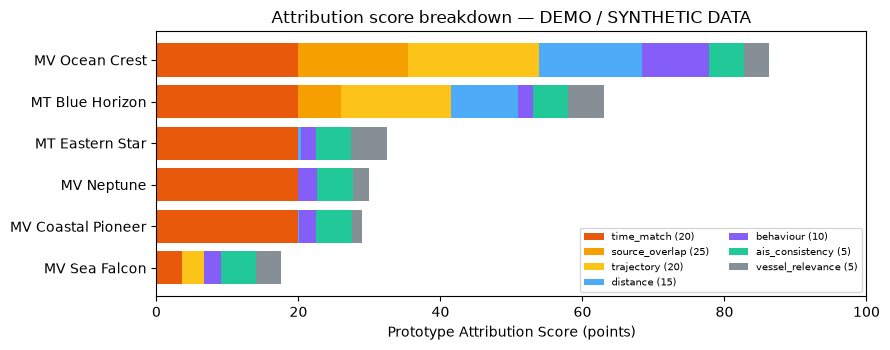

In [16]:
# Score breakdown (points out of 100, spec weights) for every candidate
fig, ax = plt.subplots(figsize=(9, 3.6))
names = [c["vessel_name"] for c in result["candidates"]][::-1]
left = np.zeros(len(names))
palette = ["#e8590c", "#f59f00", "#fcc419", "#4dabf7", "#845ef7", "#20c997", "#868e96"]
for color, key in zip(palette, A.WEIGHTS):
    vals = np.array([c["points"][key] for c in result["candidates"]][::-1])
    ax.barh(names, vals, left=left, color=color, label=f"{key} ({A.WEIGHTS[key]})")
    left += vals
ax.set_xlim(0, 100); ax.set_xlabel("Prototype Attribution Score (points)")
ax.legend(fontsize=7, ncol=2, loc="lower right"); ax.set_title("Attribution score breakdown — DEMO / SYNTHETIC DATA")
plt.tight_layout(); plt.show()

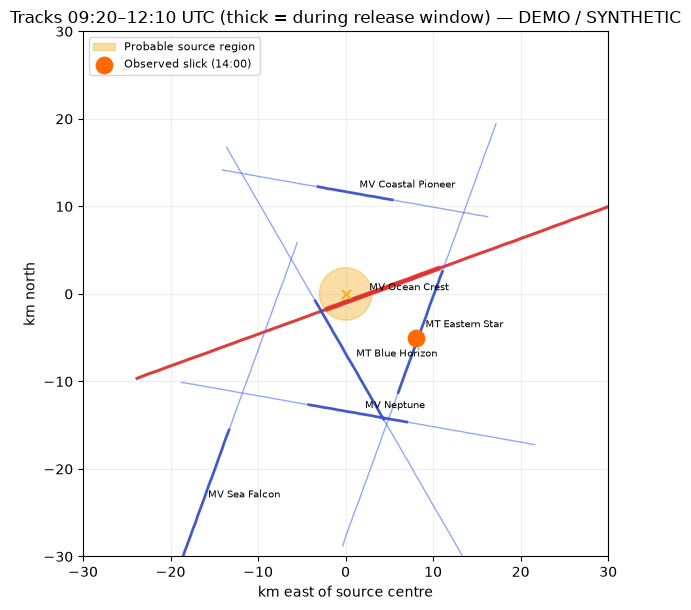

In [17]:
# Map: tracks, source region, release-window positions (local km view)
fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.add_patch(plt.Circle((0, 0), SOURCE["radius_km"], color="#f59f00", alpha=.35, label="Probable source region"))
def to_km(lat, lon): return (np.asarray(lon) - SOURCE["lon"]) * 111.32 * np.cos(np.radians(SOURCE["lat"])), (np.asarray(lat) - SOURCE["lat"]) * 110.574
for c in result["candidates"]:
    t = pd.DataFrame(c["track"]); t["time"] = pd.to_datetime(t["time"], format="ISO8601")
    x, y = to_km(t["lat"], t["lon"])
    top_ = c["rank"] == 1
    ax.plot(x, y, color="#e03131" if top_ else "#4c6ef5", lw=2.2 if top_ else 1, alpha=.95 if top_ else .6)
    w = t[t["time"].between(*WINDOW)]
    wx, wy = to_km(w["lat"], w["lon"])
    ax.plot(wx, wy, color="#e03131" if top_ else "#364fc7", lw=3.5 if top_ else 2, alpha=.9)
    mid = w.iloc[len(w) // 2] if len(w) else t.iloc[len(t) // 2]
    mx, my = to_km(mid["lat"], mid["lon"]); ax.annotate(c["vessel_name"], (mx, my), fontsize=7, xytext=(4, 4), textcoords="offset points")
sx, sy = to_km(spill["spill_lat"], spill["spill_lon"])
ax.scatter([sx], [sy], s=140, color="#ff6b00", marker="o", label="Observed slick (14:00)", zorder=5)
ax.scatter([0], [0], s=40, color="#fab005", marker="x", zorder=6)
ax.set_xlim(-30, 30); ax.set_ylim(-30, 30); ax.set_aspect("equal"); ax.grid(alpha=.2)
ax.set_xlabel("km east of source centre"); ax.set_ylabel("km north"); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Tracks 09:20–12:10 UTC (thick = during release window) — DEMO / SYNTHETIC")
plt.tight_layout(); plt.show()

## 8. SAR–AIS consistency check
SAR-detected ships at the acquisition time (14:00 UTC) are matched with AIS positions interpolated to the same instant.
SAR detections below are **synthetic** (AIS position + small geolocation error, plus one ship with no AIS). In production, pass your
real SAR ship detections in the same `[{"id","lat","lon"}]` format. An unmatched ship is a flag — **not** evidence of guilt.

In [18]:
rng = np.random.default_rng(11)
FOOT = {"lat": spill["spill_lat"], "lon": spill["spill_lon"], "radius_km": 70.0}   # SAR scene coverage
sar = []
for name, g in demo_clean.groupby("vessel_name"):
    p = A.interpolate_track(g, pd.DatetimeIndex([ACQ]))
    if p["covered"].iloc[0] and A.haversine_km(FOOT["lat"], FOOT["lon"], p["lat"].iloc[0], p["lon"].iloc[0]) <= FOOT["radius_km"]:
        sar.append({"lat": float(p["lat"].iloc[0]) + rng.normal(0, .0015), "lon": float(p["lon"].iloc[0]) + rng.normal(0, .0015)})
# one ship seen by SAR but silent on AIS, ~6 km from the slick (4 km west, 4.5 km north of it)
dark_lat = spill["spill_lat"] + 4.5 / 110.574
dark_lon = spill["spill_lon"] - 4.0 / (111.32 * np.cos(np.radians(SOURCE["lat"])))
sar.append({"lat": dark_lat, "lon": dark_lon})
sar = [{"id": f"S{i+1}", **d} for i, d in enumerate(sar)]
sarc = A.sar_ais_consistency(demo_clean, sar, ACQ, footprint=FOOT)
print(f"SAR detected vessels: {sarc['sar_detected']} | AIS matched: {sarc['ais_matched']} | "
      f"Potential AIS-inconsistent: {sarc['potential_ais_inconsistent']}")
for m_ in sarc["matches"]:  print("  matched   ", m_["sar_id"], "->", m_["vessel_name"], f"({m_['separation_km']} km)")
for u in sarc["unmatched_sar"]: print("  UNMATCHED ", u["sar_id"], "-", u["flag"], "->", u["action"])
print(sarc["note"])

SAR detected vessels: 5 | AIS matched: 4 | Potential AIS-inconsistent: 1
  matched    S1 -> MT Blue Horizon (0.22 km)
  matched    S2 -> MT Eastern Star (0.22 km)
  matched    S3 -> MV Coastal Pioneer (0.1 km)
  matched    S4 -> MV Neptune (0.1 km)
  UNMATCHED  S5 - Potential AIS-dark / inconsistent vessel -> Requires Investigation
An unmatched SAR vessel is a flag for investigation, not evidence of responsibility.


## 9. Time-slider data for the UI (10:00 → 11:30, every 15 min)

In [19]:
slider_times = pd.date_range("2026-08-15 10:00", "2026-08-15 11:30", freq="15min")
slider = []
for t in slider_times:
    frame = {"time_utc": t.isoformat(), "vessels": []}
    for mmsi, g in demo_clean.groupby("mmsi"):
        p = A.interpolate_track(g, pd.DatetimeIndex([t]))
        if p["covered"].iloc[0]:
            gg = g.sort_values("time")
            sog = float(np.interp(t.value, gg["time"].astype("int64"), gg["sog"]))
            cog = float(gg.iloc[(gg["time"] - t).abs().argmin()]["cog"])
            frame["vessels"].append({"mmsi": int(mmsi), "vessel_name": gg["vessel_name"].iloc[0], "lat": round(float(p["lat"].iloc[0]), 5),
                                     "lon": round(float(p["lon"].iloc[0]), 5), "sog_kn": round(sog, 1), "cog": round(cog, 1)})
    slider.append(frame)
print(len(slider), "frames;", len(slider[0]["vessels"]), "vessels per frame")

7 frames; 6 vessels per frame


## 10. Export the result contract for the backend

In [20]:
incident = {
    "system": "OILTRACE AI", "module": "AIS", "data_mode": "DEMO / SYNTHETIC DATA",
    "incident_id": "IND-2026-001",
    "source_region": {**SOURCE}, "release_window_utc": [WINDOW[0].isoformat(), WINDOW[1].isoformat()],
    "satellite_acquisition_utc": ACQ.isoformat(), "observed_slick_centre": spill,
    "attribution": result, "sar_ais_consistency": sarc, "slider_frames": slider,
    "cleaning_report": demo_report,
}
with open(os.path.join(OUT_DIR, "ais_incident_result.json"), "w", encoding="utf-8") as f:
    json.dump(A.to_jsonable(incident), f, indent=2)
print("wrote", os.path.join(OUT_DIR, "ais_incident_result.json"),
      f"({os.path.getsize(os.path.join(OUT_DIR, 'ais_incident_result.json')) // 1024} KB)")

wrote OILTRACE_AIS_models/ais_incident_result.json (92 KB)


## 11. Automated tests
If this cell prints `ALL TESTS PASSED`, the module behaves as documented.

In [21]:
import re
tests = []
def check(name, cond):
    tests.append((name, bool(cond))); print(("PASS  " if cond else "FAIL  ") + name)

# --- cleaning
tiny = pd.DataFrame({"MMSI": [1]*5, "BaseDateTime": pd.date_range("2026-01-01", periods=5, freq="1min"),
                     "LAT": 10 + np.arange(5)*0.003, "LON": 70.0, "SOG": [10, 102.3, 10, 10, 10],
                     "COG": [0, 360, 0, 0, 0], "Heading": [0, 511, 0, 0, 0]})
c_, r_ = A.clean_ais(tiny)
check("SOG 102.3 sentinel is not kept as data", (c_["sog"] < 50).all())
check("SOG sentinel recovered from track (about 10 kn)", abs(float(c_.loc[1, "sog"]) - 10) < 2)
check("COG 360 sentinel replaced", (c_["cog"] < 360).all())
check("no AIS missing-value code in real cleaned data", (clean["sog"] < A.AIS_SOG_NA).all() and (clean["cog"].dropna() < 360).all())
# --- features
check("features never computed across a track gap", scored.loc[scored["dt_min"] > A.SEGMENT_GAP_MIN, "anomaly_score"].isna().all() if (scored["dt_min"] > A.SEGMENT_GAP_MIN).any() else True)
check("feature list is location independent", not any(k in A.FEATURES for k in ("lat", "lon", "cog")))
# --- model
check("calibrated scores within 0-100", scored["anomaly_score"].dropna().between(0, 100).all())
check("flag rate close to contamination (1-3 %)", 0.01 <= scored["is_anomaly"].mean() <= 0.03)
check("injection AUC >= 0.90", auc >= 0.90)
# --- attribution
w_ = result["weights"]
check("weights sum to 100", sum(w_.values()) == 100)
check("scores within 0-100", all(0 <= c["attribution_score"] <= 100 for c in result["candidates"]))
check("each candidate's points sum to its score (±0.2)", all(abs(sum(c["points"].values()) - c["attribution_score"]) < 0.2 for c in result["candidates"]))
check("6 vessels found in source region", result["vessels_found_in_source_region"] == 6)
check("ranks are consecutive 1..n", [c["rank"] for c in result["candidates"]] == list(range(1, 7)))
check("top candidate is MV Ocean Crest (from scoring, not hard-coded)", result["candidates"][0]["vessel_name"] == "MV Ocean Crest")
check("top candidate flagged Anomalous + High priority", result["candidates"][0]["table"]["behaviour"] == "Anomalous" and result["candidates"][0]["status"] == "High priority")
check("score gap top vs 2nd is clear (>= 10 pts)", result["candidates"][0]["attribution_score"] - result["candidates"][1]["attribution_score"] >= 10)
by = {c["vessel_name"]: c for c in result["candidates"]}
check("Sea Falcon time match is Poor (passes ~70 min before window)", by["MV Sea Falcon"]["table"]["time_match"] == "Poor")
check("closer pass scores higher on distance factor", by["MV Ocean Crest"]["factors"]["distance"] > by["MT Blue Horizon"]["factors"]["distance"] > by["MT Eastern Star"]["factors"]["distance"])
check("real-data run anonymises names", all(re.match(r"Vessel-\d{4}$", c["vessel_name"]) for c in real_res["candidates"]))
check("disclaimer present in output", "not a legal determination" in result["disclaimer"])
check("evidence list is non-empty for top candidate", len(result["candidates"][0]["evidence"]) >= 5)
# --- interpolation honesty
g_ = demo_clean[demo_clean["mmsi"] == demo_clean["mmsi"].iloc[0]].copy()
gapped = pd.concat([g_[g_["time"] < "2026-08-15 09:00"], g_[g_["time"] > "2026-08-15 10:00"]])
p_ = A.interpolate_track(gapped, pd.DatetimeIndex(["2026-08-15 09:30"]))
check("no position invented across a 60-min AIS gap", not p_["covered"].iloc[0])
# --- SAR-AIS
check("SAR detected 5 / AIS matched 4 / 1 inconsistent", (sarc["sar_detected"], sarc["ais_matched"], sarc["potential_ais_inconsistent"]) == (5, 4, 1))
check("unmatched SAR ship is flagged for investigation, not guilt", sarc["unmatched_sar"][0]["action"] == "Requires Investigation")
# --- artifacts
check("incident JSON round-trips", json.load(open(os.path.join(OUT_DIR, "ais_incident_result.json")))["attribution"]["candidates"][0]["rank"] == 1)
check("slider has 7 frames (10:00-11:30)", len(slider) == 7)
bad = [n for n, ok in tests if not ok]
print()
print("ALL TESTS PASSED" if not bad else f"FAILED: {bad}")
assert not bad

PASS  SOG 102.3 sentinel is not kept as data
PASS  SOG sentinel recovered from track (about 10 kn)
PASS  COG 360 sentinel replaced
PASS  no AIS missing-value code in real cleaned data
PASS  features never computed across a track gap
PASS  feature list is location independent
PASS  calibrated scores within 0-100
PASS  flag rate close to contamination (1-3 %)
PASS  injection AUC >= 0.90
PASS  weights sum to 100
PASS  scores within 0-100
PASS  each candidate's points sum to its score (±0.2)
PASS  6 vessels found in source region
PASS  ranks are consecutive 1..n
PASS  top candidate is MV Ocean Crest (from scoring, not hard-coded)
PASS  top candidate flagged Anomalous + High priority
PASS  score gap top vs 2nd is clear (>= 10 pts)
PASS  Sea Falcon time match is Poor (passes ~70 min before window)
PASS  closer pass scores higher on distance factor
PASS  real-data run anonymises names
PASS  disclaimer present in output
PASS  evidence list is non-empty for top candidate


PASS  no position invented across a 60-min AIS gap
PASS  SAR detected 5 / AIS matched 4 / 1 inconsistent
PASS  unmatched SAR ship is flagged for investigation, not guilt
PASS  incident JSON round-trips
PASS  slider has 7 frames (10:00-11:30)

ALL TESTS PASSED


## 12. Handoff package

In [22]:
import zipfile
files = [os.path.join(OUT_DIR, f) for f in ["ais_anomaly_model.joblib", "ais_anomaly_model_meta.json",
                                            "demo_ais_arabian_sea.csv", "ais_incident_result.json"]] + ["oiltrace_ais.py"]
requirements = f"scikit-learn=={sklearn.__version__}\npandas>=2.0\nnumpy>=1.26\nscipy\njoblib\n"
open(os.path.join(OUT_DIR, "requirements_ais.txt"), "w").write(requirements)
files.append(os.path.join(OUT_DIR, "requirements_ais.txt"))
with zipfile.ZipFile("OILTRACE_AIS_HANDOFF.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in files:
        z.write(f, arcname=os.path.basename(f))
        print("✓", f)
print("\nCreated OILTRACE_AIS_HANDOFF.zip")
try:
    from google.colab import files as colab_files
    colab_files.download("OILTRACE_AIS_HANDOFF.zip")
except Exception:
    print("(Not in Colab - take the zip from the working directory.)")

✓ OILTRACE_AIS_models/ais_anomaly_model.joblib
✓ OILTRACE_AIS_models/ais_anomaly_model_meta.json
✓ OILTRACE_AIS_models/demo_ais_arabian_sea.csv
✓ OILTRACE_AIS_models/ais_incident_result.json
✓ oiltrace_ais.py
✓ OILTRACE_AIS_models/requirements_ais.txt

Created OILTRACE_AIS_HANDOFF.zip
(Not in Colab - take the zip from the working directory.)


## 13. Backend integration

```python
# backend/services/vessel_attribution.py
import pandas as pd, oiltrace_ais as A

MODEL = A.AISAnomalyModel.load("models/ais_anomaly_model.joblib")      # load once at startup

def attribute(ais_df: pd.DataFrame, region: dict, window: tuple[str, str], anonymize=False):
    clean, _ = A.clean_ais(ais_df)                                      # raw AIS rows -> clean tracks
    res = A.attribute_vessels(clean, A.SourceRegion(**region), *window, MODEL, anonymize=anonymize)
    return A.to_jsonable(res)                                           # JSON-ready for FastAPI
```

| Endpoint | Call |
|---|---|
| `POST /ais/candidates` | `clean_ais` → `attribute_vessels` (the candidate list = `result["candidates"]`) |
| `POST /attribute` | same result; the UI shows `evidence`, `points`, `table`, `assessment` |
| SAR–AIS panel | `A.sar_ais_consistency(clean, sar_detections, acquisition_time, footprint=...)` |
| Time slider | `slider_frames` in `ais_incident_result.json` (or call `interpolate_track`) |
| Demo mode | load `demo_ais_arabian_sea.csv` + `ais_incident_result.json`; no external API needed |

**Inputs the backend must provide:** `SourceRegion(lat, lon, radius_km)` and the release window from the hindcast;
for real data, AIS rows with `MMSI, BaseDateTime, LAT, LON, SOG, COG` (+ `VesselName, VesselType` if available).

### Limitations to state honestly
- The behaviour model was trained on **one** small Gulf-of-Mexico dataset (≈53 k records, 347 vessels); there is no ground truth for AIS anomalies.
- The 7-factor weights come from the project specification; they are **not** statistically validated.
- `vessel_relevance` is a hand-set heuristic by AIS ship-type code.
- Results are *candidates for investigation*, never proof. Never show real vessel names from the training data in the UI (use `anonymize=True`).
- Pickle files are tied to the scikit-learn version printed above.